<a href="https://colab.research.google.com/github/RZchive/Klasterisasi_Artikel_Kesehatan_Lansia_Scrapping_Data/blob/main/Big_Data_Kesehatan_Lansia_1000_Data_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyek Big Data End-to-End: Multi-Source Web Scraping, NLP Preprocessing, & Visualisasi Kesehatan Lansia (Target ≥ 1.000 Artikel)

### Strategi Multi-Source + XML Sitemap Harvesting (Target 1.500+ Kandidat URL)
Kategori `https://www.klikdokter.com/info-sehat/kesehatan-lansia` hanya memiliki sekitar **±225 artikel** dan menggunakan rendering dinamis pada tombol *pagination*-nya. Untuk menembus minimal **1.000 data bersih** secara valid tanpa duplikasi, pipeline ini menggabungkan **5 sumber terpercaya** dengan metode *pagination* + *XML Sitemap filtering*:

1. **KlikDokter** (`klikdokter.com/info-sehat/kesehatan-lansia` + XML Sitemap artikel lansia) — ±225–300 artikel
2. **HelloSehat** (`hellosehat.com/lansia/` & sub-kategorinya) — ±200–250 artikel
3. **Kompas.com** (`kompas.com/tag/lansia` & `/tag/kesehatan-lansia`) — ±250–400 artikel
4. **Detik.com** (`detik.com/tag/kesehatan-lansia` & `/tag/lansia`) — ±500+ artikel
5. **AntaraNews** (`antaranews.com/tag/lansia`) — ±500+ artikel

**Alur Pipeline:**
1. **Tahap 1 (Data Acquisition):** Crawling indeks URL (target 1.500+ kandidat unik) → Ekstraksi konten & metadata otomatis via **JSON-LD (`application/ld+json`) + BeautifulSoup** → *Auto-checkpoint* setiap 100 data → Output `dataset_lansia_raw.csv`.
2. **Tahap 2 (Data Cleaning & NLP):** Deduplikasi, standarisasi tanggal, pembersihan HTML, *case folding*, penghapusan *stopwords* Bahasa Indonesia (`Sastrawi`), perhitungan jumlah kata → Output `dataset_lansia_clean.csv` & `.parquet`.
3. **Tahap 3 (EDA & Visualisasi):** Analisis distribusi sumber, tren publikasi waktu, Top 15 kata kunci/penyakit, WordCloud, distribusi panjang artikel, dan *Topic Modeling* (LDA 5 Klaster Topik).

In [ ]:
# Jalankan cell ini sekali untuk memastikan semua library terinstal (cocok untuk Google Colab maupun Jupyter Lokal)
!pip install -q requests beautifulsoup4 lxml pandas numpy matplotlib seaborn wordcloud Sastrawi scikit-learn tqdm pyarrow

import os
import re
import json
import time
import random
from datetime import datetime
from urllib.parse import urljoin, urlparse

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Konfigurasi tampilan
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams['figure.dpi'] = 120

print("Semua library berhasil di-import!")

Semua library berhasil di-import!


---
## Tahap 1: Multi-Source Web Scraping (Target ≥ 1.000 Artikel Unik)

### Mengapa Ekstraksi Hibrida (JSON-LD + HTML Fallback) + XML Sitemap Sangat Efektif?
1. **XML Sitemap + Multi-Pattern Pagination:** Situs seperti KlikDokter menggunakan *client-side pagination* sehingga `?page=2` hanya menampilkan 11 link awal. Dengan membaca `sitemap.xml` resmi milik KlikDokter dan menyaring slug bertema lansia/geriatri, skrip langsung memperoleh ratusan URL artikel tanpa terhalang *JavaScript pagination*.
2. **JSON-LD (`application/ld+json`):** Mengekstrak `judul`, `tanggal_publikasi`, `penulis`, dan `isi_artikel` secara seragam lintas portal.

In [ ]:
USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.5 Safari/605.1.15",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/127.0.0.0 Safari/537.36",
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:129.0) Gecko/20100101 Firefox/129.0"
]

def create_resilient_session():
    session = requests.Session()
    retries = Retry(
        total=3,
        backoff_factor=1.5,
        status_forcelist=[429, 500, 502, 503, 504],
        allowed_methods=["GET"]
    )
    adapter = HTTPAdapter(max_retries=retries)
    session.mount("http://", adapter)
    session.mount("https://", adapter)
    return session

def get_headers():
    return {
        "User-Agent": random.choice(USER_AGENTS),
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
        "Accept-Language": "id-ID,id;q=0.9,en-US;q=0.8,en;q=0.7",
        "Referer": "https://www.google.com/"
    }

def _parse_json_ld_objects(soup):
    items = []
    for script in soup.find_all("script", type="application/ld+json"):
        raw = script.string or script.get_text()
        if not raw:
            continue
        try:
            data = json.loads(raw.strip())
            if isinstance(data, list):
                items.extend(data)
            elif isinstance(data, dict):
                if "@graph" in data and isinstance(data["@graph"], list):
                    items.extend(data["@graph"])
                else:
                    items.append(data)
        except Exception:
            continue
    return items

def extract_article_detail(session, url, sumber):
    try:
        resp = session.get(url, headers=get_headers(), timeout=15)
        if resp.status_code != 200:
            return None
        soup = BeautifulSoup(resp.text, "lxml")

        judul = ""
        tanggal = ""
        penulis = ""
        kategori = "Kesehatan Lansia"
        tags = ""
        isi_artikel = ""

        # 1. Ekstraksi dari JSON-LD (Schema.org NewsArticle / MedicalWebPage / Article)
        ld_objects = _parse_json_ld_objects(soup)
        for obj in ld_objects:
            if not isinstance(obj, dict):
                continue
            obj_type = str(obj.get("@type", ""))
            if any(t in obj_type for t in ["Article", "MedicalWebPage", "WebPage"]):
                if not judul and obj.get("headline"):
                    judul = str(obj.get("headline")).strip()
                if not tanggal and obj.get("datePublished"):
                    tanggal = str(obj.get("datePublished")).strip()
                if not penulis and obj.get("author"):
                    auth = obj.get("author")
                    if isinstance(auth, dict):
                        penulis = auth.get("name", "")
                    elif isinstance(auth, list) and len(auth) > 0:
                        penulis = auth[0].get("name", "") if isinstance(auth[0], dict) else str(auth[0])
                    else:
                        penulis = str(auth)
                if not tags and obj.get("keywords"):
                    kw = obj.get("keywords")
                    tags = ", ".join(kw) if isinstance(kw, list) else str(kw)
                if not isi_artikel and obj.get("articleBody"):
                    isi_artikel = str(obj.get("articleBody")).strip()

        # 2. Fallback & Pelengkap dari Tag HTML / Meta OpenGraph
        if not judul:
            h1 = soup.find("h1")
            if h1:
                judul = h1.get_text(" ", strip=True)
            else:
                og_title = soup.find("meta", property="og:title")
                judul = og_title["content"].strip() if og_title and og_title.get("content") else ""

        if not tanggal:
            meta_date = (
                soup.find("meta", property="article:published_time")
                or soup.find("meta", attrs={"name": "publishdate"})
                or soup.find("meta", attrs={"name": "pubdate"})
                or soup.find("time")
            )
            if meta_date:
                tanggal = meta_date.get("content") or meta_date.get("datetime") or meta_date.get_text(strip=True)

        if not tags:
            meta_kw = soup.find("meta", attrs={"name": "keywords"})
            if meta_kw and meta_kw.get("content"):
                tags = meta_kw["content"].strip()

        # Ekstrak paragraf artikel jika articleBody dari JSON-LD kosong atau terlalu pendek
        if len(isi_artikel) < 200:
            container = soup.find("article") or soup.find("div", class_=re.compile(r"(article|content|read__content|detail__body)", re.I)) or soup
            paragraphs = []
            for p in container.find_all("p"):
                txt = p.get_text(" ", strip=True)
                if len(txt) > 40 and not any(skip in txt.lower() for skip in ["baca juga:", "simak video", "advertisement", "copyright"]):
                    paragraphs.append(txt)
            if paragraphs:
                isi_artikel = " ".join(paragraphs)

        # Validasi minimal agar data berkualitas
        if not judul or len(isi_artikel) < 120:
            return None

        return {
            "sumber": sumber,
            "url_artikel": url,
            "judul": judul,
            "tanggal_publikasi": tanggal,
            "kategori": kategori,
            "penulis": penulis if penulis else f"Redaksi {sumber}",
            "tags": tags,
            "isi_artikel": isi_artikel
        }
    except Exception:
        return None

print("Fungsi ekstraktor universal siap digunakan.")

Fungsi ekstraktor universal siap digunakan.


In [ ]:
LANSIA_KEYWORDS_RE = re.compile(
    r"(lansia|lanjut-usia|geriatri|manula|demensia|alzheimer|pikun|osteoporosis|pensiun|orang-tua|menopause|kakek|nenek)",
    re.I
)

def collect_klikdokter_urls(session, max_pages=25):
    urls = set()
    # A. Crawling halaman kategori & topik (format ?page= dan /page/)
    base_urls = [
        "https://www.klikdokter.com/info-sehat/kesehatan-lansia",
        "https://www.klikdokter.com/topik/lansia"
    ]
    for base in base_urls:
        for page in range(1, max_pages + 1):
            candidates_page = [base] if page == 1 else [f"{base}?page={page}", f"{base}/page/{page}"]
            found_in_page = 0
            for target in candidates_page:
                try:
                    r = session.get(target, headers=get_headers(), timeout=15)
                    if r.status_code != 200:
                        continue
                    soup = BeautifulSoup(r.text, "lxml")
                    for a in soup.find_all("a", href=True):
                        href = urljoin("https://www.klikdokter.com", a["href"].split("?")[0])
                        if "/info-sehat/" in href and href.count("/") >= 5 and href not in urls:
                            urls.add(href)
                            found_in_page += 1
                    if found_in_page > 0:
                        break
                except Exception:
                    continue
            if found_in_page == 0 and page > 1:
                break
            time.sleep(random.uniform(0.4, 0.9))

    # B. XML Sitemap Harvesting untuk menembus limit SSR pagination KlikDokter
    try:
        sm_index = session.get("https://www.klikdokter.com/sitemap.xml", headers=get_headers(), timeout=15)
        if sm_index.status_code == 200:
            sub_sitemaps = re.findall(r"<loc>(https://www\.klikdokter\.com/[^<]+sitemap[^<]*\.xml)</loc>", sm_index.text)
            for sm_url in sub_sitemaps[:20]:
                try:
                    r_sm = session.get(sm_url, headers=get_headers(), timeout=15)
                    if r_sm.status_code != 200:
                        continue
                    locs = re.findall(r"<loc>(https://www\.klikdokter\.com/info-sehat/[^<]+)</loc>", r_sm.text)
                    for loc in locs:
                        if loc.count("/") >= 5 and LANSIA_KEYWORDS_RE.search(loc):
                            urls.add(loc.split("?")[0])
                    time.sleep(0.3)
                except Exception:
                    continue
    except Exception:
        pass

    return list(urls)

def collect_hellosehat_urls(session, max_pages=30):
    urls = set()
    categories = [
        "https://hellosehat.com/lansia/",
        "https://hellosehat.com/lansia/masalah-lansia/",
        "https://hellosehat.com/lansia/olahraga-lansia/",
        "https://hellosehat.com/lansia/gizi-lansia/"
    ]
    for cat in categories:
        for page in range(1, max_pages + 1):
            candidates_page = [cat] if page == 1 else [f"{cat}page/{page}/", f"{cat}?page={page}"]
            found_in_page = 0
            for target in candidates_page:
                try:
                    r = session.get(target, headers=get_headers(), timeout=15)
                    if r.status_code != 200:
                        continue
                    soup = BeautifulSoup(r.text, "lxml")
                    for a in soup.find_all("a", href=True):
                        href = urljoin("https://hellosehat.com", a["href"].split("?")[0])
                        if href.startswith("https://hellosehat.com/lansia/") and href.count("/") >= 5 and "/page/" not in href:
                            if href not in urls:
                                urls.add(href)
                                found_in_page += 1
                    if found_in_page > 0:
                        break
                except Exception:
                    continue
            if found_in_page == 0 and page > 1:
                break
            time.sleep(random.uniform(0.4, 0.9))
    return list(urls)

def collect_kompas_urls(session, max_pages=35):
    urls = set()
    tag_bases = [
        "https://www.kompas.com/tag/kesehatan-lansia",
        "https://www.kompas.com/tag/lansia",
        "https://www.kompas.com/tag/demensia"
    ]
    for base in tag_bases:
        for page in range(1, max_pages + 1):
            candidates_page = [f"{base}?page={page}", f"{base}/{page}"]
            found_in_page = 0
            for target in candidates_page:
                try:
                    r = session.get(target, headers=get_headers(), timeout=15)
                    if r.status_code != 200:
                        continue
                    soup = BeautifulSoup(r.text, "lxml")
                    for a in soup.find_all("a", href=True):
                        href = a["href"].split("?")[0]
                        if ".kompas.com/read/" in href and href not in urls:
                            urls.add(href)
                            found_in_page += 1
                    if found_in_page > 0:
                        break
                except Exception:
                    continue
            if found_in_page == 0 and page > 1:
                break
            time.sleep(random.uniform(0.4, 0.9))
    return list(urls)

def collect_detik_urls(session, max_pages=45):
    urls = set()
    tag_bases = [
        "https://www.detik.com/tag/kesehatan-lansia",
        "https://www.detik.com/tag/lansia"
    ]
    for base in tag_bases:
        for page in range(1, max_pages + 1):
            target = f"{base}/?page={page}"
            try:
                r = session.get(target, headers=get_headers(), timeout=15)
                if r.status_code != 200:
                    break
                soup = BeautifulSoup(r.text, "lxml")
                found_in_page = 0
                for a in soup.find_all("a", href=True):
                    href = a["href"].split("?")[0]
                    if re.search(r"detik\.com/.+/d-\d+/", href):
                        if href not in urls:
                            urls.add(href)
                            found_in_page += 1
                if found_in_page == 0:
                    break
                time.sleep(random.uniform(0.4, 0.9))
            except Exception:
                continue
    return list(urls)

def collect_antara_urls(session, max_pages=40):
    urls = set()
    for page in range(1, max_pages + 1):
        target = f"https://www.antaranews.com/tag/lansia/{page}"
        try:
            r = session.get(target, headers=get_headers(), timeout=15)
            if r.status_code != 200:
                break
            soup = BeautifulSoup(r.text, "lxml")
            found_in_page = 0
            for a in soup.find_all("a", href=True):
                href = a["href"].split("?")[0]
                if "antaranews.com/berita/" in href and href not in urls:
                    urls.add(href)
                    found_in_page += 1
            if found_in_page == 0:
                break
            time.sleep(random.uniform(0.4, 0.9))
        except Exception:
            continue
    return list(urls)

# Jalankan pengumpulan indeks URL dari ke-5 sumber
session = create_resilient_session()

print("1/5 Mengumpulkan indeks URL KlikDokter (Pagination + XML Sitemap)...")
urls_kd = collect_klikdokter_urls(session, max_pages=25)
print(f"    -> Ditemukan {len(urls_kd)} kandidat URL KlikDokter")

print("2/5 Mengumpulkan indeks URL HelloSehat...")
urls_hs = collect_hellosehat_urls(session, max_pages=30)
print(f"    -> Ditemukan {len(urls_hs)} kandidat URL HelloSehat")

print("3/5 Mengumpulkan indeks URL Kompas...")
urls_kp = collect_kompas_urls(session, max_pages=35)
print(f"    -> Ditemukan {len(urls_kp)} kandidat URL Kompas")

print("4/5 Mengumpulkan indeks URL Detik...")
urls_dt = collect_detik_urls(session, max_pages=45)
print(f"    -> Ditemukan {len(urls_dt)} kandidat URL Detik")

print("5/5 Mengumpulkan indeks URL AntaraNews...")
urls_an = collect_antara_urls(session, max_pages=40)
print(f"    -> Ditemukan {len(urls_an)} kandidat URL AntaraNews")

all_candidates = (
    [("KlikDokter", u) for u in urls_kd] +
    [("HelloSehat", u) for u in urls_hs] +
    [("Kompas", u) for u in urls_kp] +
    [("Detik", u) for u in urls_dt] +
    [("AntaraNews", u) for u in urls_an]
)

df_candidates = pd.DataFrame(all_candidates, columns=["sumber", "url"]).drop_duplicates(subset=["url"])
print(f"\nTotal kandidat URL unik gabungan: {len(df_candidates)} URL")
display(df_candidates["sumber"].value_counts())

1/5 Mengumpulkan indeks URL KlikDokter (Pagination + XML Sitemap)...
    -> Ditemukan 11 kandidat URL KlikDokter
2/5 Mengumpulkan indeks URL HelloSehat...
    -> Ditemukan 160 kandidat URL HelloSehat
3/5 Mengumpulkan indeks URL Kompas...
    -> Ditemukan 0 kandidat URL Kompas
4/5 Mengumpulkan indeks URL Detik...
    -> Ditemukan 540 kandidat URL Detik
5/5 Mengumpulkan indeks URL AntaraNews...
    -> Ditemukan 601 kandidat URL AntaraNews

Total kandidat URL unik gabungan: 1312 URL


,count
sumber,
AntaraNews,601
Detik,540
HelloSehat,160
KlikDokter,11


In [ ]:
TARGET_ARTIKEL = 1150  # Mengambil 1.150 artikel agar setelah cleaning tetap >= 1.000 data bersih
RAW_OUTPUT_FILE = "dataset_lansia_raw.csv"
CHECKPOINT_FILE = "dataset_lansia_checkpoint.csv"

# Muat checkpoint jika sebelumnya sudah sempat berjalan
scraped_records = []
scraped_urls = set()

if os.path.exists(CHECKPOINT_FILE):
    df_prev = pd.read_csv(CHECKPOINT_FILE)
    scraped_records = df_prev.to_dict("records")
    scraped_urls = set(df_prev["url_artikel"].dropna().tolist())
    print(f"Melanjutkan dari checkpoint: {len(scraped_records)} artikel sudah tersimpan.")

# Prioritaskan seluruh KlikDokter & HelloSehat terlebih dahulu, lalu acak sumber berita lainnya agar seimbang
df_priority = df_candidates[df_candidates["sumber"].isin(["KlikDokter", "HelloSehat"])]
df_secondary = df_candidates[~df_candidates["sumber"].isin(["KlikDokter", "HelloSehat"])].sample(frac=1, random_state=42)
df_queue = pd.concat([df_priority, df_secondary], ignore_index=True)

pbar = tqdm(total=TARGET_ARTIKEL, initial=len(scraped_records), desc="Scraping Artikel Lansia")

for idx, row in df_queue.iterrows():
    if len(scraped_records) >= TARGET_ARTIKEL:
        break

    url = row["url"]
    sumber = row["sumber"]

    if url in scraped_urls:
        continue

    article_data = extract_article_detail(session, url, sumber)
    if article_data:
        scraped_records.append(article_data)
        scraped_urls.add(url)
        pbar.update(1)

        # Checkpoint auto-save setiap 100 artikel
        if len(scraped_records) % 100 == 0:
            pd.DataFrame(scraped_records).to_csv(CHECKPOINT_FILE, index=False, encoding="utf-8-sig")

    # Etika scraping: jeda acak antar request
    time.sleep(random.uniform(0.5, 1.2))

pbar.close()

df_raw = pd.DataFrame(scraped_records)
df_raw.to_csv(RAW_OUTPUT_FILE, index=False, encoding="utf-8-sig")
print(f"\nSelesai! Total data mentah tersimpan di '{RAW_OUTPUT_FILE}': {len(df_raw)} baris.")
display(df_raw.groupby("sumber").size().rename("jumlah_artikel"))

Scraping Artikel Lansia:   0%|          | 0/1150 [00:00<?, ?it/s]


Selesai! Total data mentah tersimpan di 'dataset_lansia_raw.csv': 686 baris.


,jumlah_artikel
sumber,
AntaraNews,2
Detik,532
HelloSehat,141
KlikDokter,11


In [ ]:
import os
import re
import json
import time
import random
from concurrent.futures import ThreadPoolExecutor, as_completed
import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
import pandas as pd
from tqdm.auto import tqdm

# 1. Muat 686 data yang sudah tersimpan agar tidak ada duplikat saat append
RAW_FILE = "dataset_lansia_raw.csv"
TARGET_TOTAL = 1150

if os.path.exists(RAW_FILE):
    df_existing = pd.read_csv(RAW_FILE)
    existing_records = df_existing.to_dict("records")
    seen_urls = set(df_existing["url_artikel"].dropna().str.strip().tolist())
    seen_titles = set(df_existing["judul"].dropna().str.lower().str.strip().tolist())
    print(f"Data awal dimuat dari '{RAW_FILE}': {len(existing_records)} baris unik.")
else:
    existing_records = []
    seen_urls = set()
    seen_titles = set()
    print("File lama tidak ditemukan, memulai dari 0.")

USER_AGENTS = [
    "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
    "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.5 Safari/605.1.15",
    "Mozilla/5.0 (X11; Linux x86_64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/127.0.0.0 Safari/537.36"
]

def make_fast_session():
    s = requests.Session()
    retries = Retry(total=1, backoff_factor=0.5, status_forcelist=[429, 500, 502, 503, 504])
    adapter = HTTPAdapter(max_retries=retries, pool_connections=10, pool_maxsize=10)
    s.mount("http://", adapter)
    s.mount("https://", adapter)
    return s

def headers_rand():
    return {
        "User-Agent": random.choice(USER_AGENTS),
        "Accept": "text/html,application/xhtml+xml,application/xml;q=0.9,*/*;q=0.8",
        "Accept-Language": "id-ID,id;q=0.9,en-US;q=0.8"
    }

session = make_fast_session()

# 2. Kumpulkan kandidat URL BARU dari kanal kesehatan & tag lansia tambahan
def harvest_new_urls():
    new_candidates = []
    temp_seen = set(seen_urls)

    def add_url(sumber, url):
        clean_u = url.split("?")[0].strip()
        if clean_u not in temp_seen:
            temp_seen.add(clean_u)
            new_candidates.append((sumber, clean_u))

    # A. DetikHealth Search (siteid=3 khusus kanal kesehatan Detik)
    detik_queries = ["kesehatan+lansia", "penyakit+lansia", "demensia", "osteoporosis", "geriatri"]
    for q in detik_queries:
        for page in range(1, 20):
            target = f"https://www.detik.com/search/searchall?query={q}&siteid=3&page={page}"
            try:
                r = session.get(target, headers=headers_rand(), timeout=8)
                if r.status_code != 200:
                    break
                soup = BeautifulSoup(r.text, "lxml")
                found = 0
                for a in soup.find_all("a", href=True):
                    href = a["href"]
                    if re.search(r"health\.detik\.com/.+/d-\d+/", href):
                        add_url("DetikHealth", href)
                        found += 1
                if found == 0:
                    break
            except Exception:
                break

    # B. CNN Indonesia (Tag Lansia & Kesehatan Lansia)
    for tag in ["lansia", "kesehatan-lansia", "demensia"]:
        for page in range(1, 25):
            target = f"https://www.cnnindonesia.com/tag/{tag}/{page}"
            try:
                r = session.get(target, headers=headers_rand(), timeout=8)
                if r.status_code != 200:
                    break
                soup = BeautifulSoup(r.text, "lxml")
                found = 0
                for a in soup.find_all("a", href=True):
                    href = a["href"]
                    if "cnnindonesia.com/gaya-hidup/" in href or "cnnindonesia.com/nasional/" in href:
                        if re.search(r"/\d{14}-\d+-\d+/", href):
                            add_url("CNNIndonesia", href)
                            found += 1
                if found == 0:
                    break
            except Exception:
                break

    # C. Liputan6 (Tag Lansia & Kesehatan Lansia)
    for tag in ["lansia", "kesehatan-lansia"]:
        for page in range(1, 30):
            target = f"https://www.liputan6.com/tag/{tag}?page={page}"
            try:
                r = session.get(target, headers=headers_rand(), timeout=8)
                if r.status_code != 200:
                    break
                soup = BeautifulSoup(r.text, "lxml")
                found = 0
                for a in soup.find_all("a", href=True):
                    href = a["href"]
                    if "liputan6.com/health/read/" in href or "liputan6.com/lifestyle/read/" in href:
                        add_url("Liputan6", href)
                        found += 1
                if found == 0:
                    break
            except Exception:
                break

    # D. Suara.com (Tag Lansia & Kesehatan Lansia)
    for tag in ["lansia", "kesehatan-lansia"]:
        for page in range(1, 25):
            target = f"https://www.suara.com/tag/{tag}?page={page}"
            try:
                r = session.get(target, headers=headers_rand(), timeout=8)
                if r.status_code != 200:
                    break
                soup = BeautifulSoup(r.text, "lxml")
                found = 0
                for a in soup.find_all("a", href=True):
                    href = a["href"]
                    if "suara.com/health/" in href or "suara.com/lifestyle/" in href:
                        add_url("Suara", href)
                        found += 1
                if found == 0:
                    break
            except Exception:
                break

    return new_candidates

print("Mencari kandidat URL baru yang belum ada di dataset...")
fresh_candidates = harvest_new_urls()
random.shuffle(fresh_candidates)
print(f"Ditemukan {len(fresh_candidates)} kandidat URL baru siap di-scrape!")

# 3. Fungsi ekstraksi artikel cepat
def fetch_single_article(item):
    sumber, url = item
    try:
        resp = session.get(url, headers=headers_rand(), timeout=8)
        if resp.status_code != 200:
            return None
        soup = BeautifulSoup(resp.text, "lxml")

        judul, tanggal, penulis, tags, isi_artikel = "", "", "", "", ""

        for script in soup.find_all("script", type="application/ld+json"):
            raw = script.string or script.get_text()
            if not raw:
                continue
            try:
                data = json.loads(raw.strip())
                objs = data if isinstance(data, list) else data.get("@graph", [data])
                for obj in objs:
                    if not isinstance(obj, dict):
                        continue
                    if any(t in str(obj.get("@type", "")) for t in ["Article", "MedicalWebPage", "WebPage"]):
                        judul = judul or str(obj.get("headline", "")).strip()
                        tanggal = tanggal or str(obj.get("datePublished", "")).strip()
                        if not penulis and obj.get("author"):
                            auth = obj["author"]
                            penulis = auth[0].get("name", "") if isinstance(auth, list) and isinstance(auth[0], dict) else (auth.get("name", "") if isinstance(auth, dict) else str(auth))
                        if not tags and obj.get("keywords"):
                            kw = obj["keywords"]
                            tags = ", ".join(kw) if isinstance(kw, list) else str(kw)
                        isi_artikel = isi_artikel or str(obj.get("articleBody", "")).strip()
            except Exception:
                continue

        if not judul:
            h1 = soup.find("h1")
            judul = h1.get_text(" ", strip=True) if h1 else ""

        if not tanggal:
            meta_d = soup.find("meta", property="article:published_time") or soup.find("meta", attrs={"name": "publishdate"})
            if meta_d and meta_d.get("content"):
                tanggal = meta_d["content"].strip()

        if len(isi_artikel) < 200:
            container = soup.find("article") or soup.find("div", class_=re.compile(r"(detail__body|read__content|article-content|content)", re.I)) or soup
            paras = [
                p.get_text(" ", strip=True) for p in container.find_all("p")
                if len(p.get_text(strip=True)) > 40 and not any(x in p.get_text().lower() for x in ["baca juga:", "simak video", "advertisement"])
            ]
            if paras:
                isi_artikel = " ".join(paras)

        if not judul or len(isi_artikel) < 120:
            return None

        return {
            "sumber": sumber,
            "url_artikel": url,
            "judul": judul,
            "tanggal_publikasi": tanggal,
            "kategori": "Kesehatan Lansia",
            "penulis": penulis if penulis else f"Redaksi {sumber}",
            "tags": tags,
            "isi_artikel": isi_artikel
        }
    except Exception:
        return None

# 4. Jalankan scraping paralel ringan & append otomatis ke dataset_lansia_raw.csv
needed = max(0, TARGET_TOTAL - len(existing_records))
print(f"Membutuhkan {needed} artikel tambahan untuk mencapai {TARGET_TOTAL} baris...\n")

pbar = tqdm(total=TARGET_TOTAL, initial=len(existing_records), desc="Melanjutkan Scraping")

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = [executor.submit(fetch_single_article, item) for item in fresh_candidates]
    for fut in as_completed(futures):
        if len(existing_records) >= TARGET_TOTAL:
            for f in futures:
                f.cancel()
            break

        res = fut.result()
        if res:
            norm_title = res["judul"].lower().strip()
            if res["url_artikel"] not in seen_urls and norm_title not in seen_titles:
                existing_records.append(res)
                seen_urls.add(res["url_artikel"])
                seen_titles.add(norm_title)
                pbar.update(1)

                # Auto-save langsung ke dataset_lansia_raw.csv setiap 50 data baru
                if len(existing_records) % 50 == 0:
                    pd.DataFrame(existing_records).to_csv(RAW_FILE, index=False, encoding="utf-8-sig")

pbar.close()

df_final_raw = pd.DataFrame(existing_records)
df_final_raw.to_csv(RAW_FILE, index=False, encoding="utf-8-sig")

print(f"\nSelesai! Total data mentah gabungan di '{RAW_FILE}': {len(df_final_raw)} baris.")
display(df_final_raw.groupby("sumber").size().rename("jumlah_artikel"))

Data awal dimuat dari 'dataset_lansia_raw.csv': 686 baris unik.
Mencari kandidat URL baru yang belum ada di dataset...
Ditemukan 193 kandidat URL baru siap di-scrape!
Membutuhkan 464 artikel tambahan untuk mencapai 1150 baris...



Melanjutkan Scraping:  60%|#####9    | 686/1150 [00:00<?, ?it/s]


Selesai! Total data mentah gabungan di 'dataset_lansia_raw.csv': 718 baris.


,jumlah_artikel
sumber,
AntaraNews,2
Detik,532
HelloSehat,141
KlikDokter,11
Liputan6,32


In [ ]:
from concurrent.futures import ThreadPoolExecutor, as_completed

RAW_FILE = "dataset_lansia_raw.csv"
TARGET_TOTAL = 1150

# 1. Muat 718 data lama agar tidak ada duplikat
df_existing = pd.read_csv(RAW_FILE)
existing_records = df_existing.to_dict("records")
seen_urls = set(df_existing["url_artikel"].dropna().str.strip())
seen_titles = set(df_existing["judul"].dropna().str.lower().str.strip())
print(f"Data awal dimuat: {len(existing_records)} baris.")

# 2. Kumpulkan kandidat URL baru dari tag geriatri tambahan
new_candidates = []
temp_seen = set(seen_urls)

def add_url(sumber, url):
    u = url.split("?")[0].strip()
    if u not in temp_seen:
        temp_seen.add(u)
        new_candidates.append((sumber, u))

tags_tambahan = ["lanjut-usia", "demensia", "alzheimer", "osteoporosis", "pikun", "manula", "geriatri"]

for tag in tags_tambahan:
    # Detik
    for page in range(1, 20):
        try:
            r = session.get(f"https://www.detik.com/tag/{tag}/?page={page}", headers=get_headers(), timeout=10)
            if r.status_code != 200: break
            links = [a["href"] for a in BeautifulSoup(r.text, "lxml").find_all("a", href=True) if re.search(r"detik\.com/.+/d-\d+/", a["href"])]
            if not links: break
            for h in links: add_url("Detik", h)
        except Exception: break

    # Liputan6
    for page in range(1, 20):
        try:
            r = session.get(f"https://www.liputan6.com/tag/{tag}?page={page}", headers=get_headers(), timeout=10)
            if r.status_code != 200: break
            links = [a["href"] for a in BeautifulSoup(r.text, "lxml").find_all("a", href=True) if re.search(r"liputan6\.com/.+/read/\d+/", a["href"])]
            if not links: break
            for h in links: add_url("Liputan6", h)
        except Exception: break

random.shuffle(new_candidates)
print(f"Kandidat URL baru ditemukan: {len(new_candidates)} tautan.")

# 3. Ambil artikel memakai fungsi extract_article_detail dari Cell 1 & append
pbar = tqdm(total=TARGET_TOTAL, initial=len(existing_records), desc="Append ke 1150")

with ThreadPoolExecutor(max_workers=4) as executor:
    futures = {executor.submit(extract_article_detail, session, url, src): (src, url) for src, url in new_candidates}
    for fut in as_completed(futures):
        if len(existing_records) >= TARGET_TOTAL:
            for f in futures: f.cancel()
            break
        res = fut.result()
        if res:
            title_norm = res["judul"].lower().strip()
            if res["url_artikel"] not in seen_urls and title_norm not in seen_titles:
                existing_records.append(res)
                seen_urls.add(res["url_artikel"])
                seen_titles.add(title_norm)
                pbar.update(1)
                if len(existing_records) % 50 == 0:
                    pd.DataFrame(existing_records).to_csv(RAW_FILE, index=False, encoding="utf-8-sig")

pbar.close()

df_raw = pd.DataFrame(existing_records)
df_raw.to_csv(RAW_FILE, index=False, encoding="utf-8-sig")
print(f"\nSelesai! Total data di '{RAW_FILE}': {len(df_raw)} baris.")
display(df_raw.groupby("sumber").size().rename("jumlah_artikel"))

Data awal dimuat: 718 baris.
Kandidat URL baru ditemukan: 1467 tautan.


Append ke 1150:  62%|######2   | 718/1150 [00:00<?, ?it/s]


Selesai! Total data di 'dataset_lansia_raw.csv': 1150 baris.


,jumlah_artikel
sumber,
AntaraNews,2
Detik,659
HelloSehat,141
KlikDokter,11
Liputan6,337


---
## Tahap 2: Data Cleaning & NLP Preprocessing Bahasa Indonesia

Pada tahap ini, dataset mentah (`dataset_lansia_raw.csv`) diproses agar siap untuk analisis Big Data dan pemodelan topik:
1. **Deduplikasi & Validasi:** Menghapus duplikat berdasarkan `url_artikel` dan kemiripan `judul`, serta memastikan `isi_artikel` memiliki minimal 30 kata.
2. **Standarisasi Tanggal:** Mengonversi berbagai format tanggal portal berita/kesehatan menjadi `datetime` standar (`YYYY-MM-DD`), serta mengekstrak `tahun`, `bulan`, dan `tahun_bulan`.
3. **Text Preprocessing (NLP Bahasa Indonesia):**
   - Menghapus tag HTML sisa, URL, angka, dan tanda baca.
   - *Case folding* (konversi ke huruf kecil).
   - Penghapusan *stopwords* Bahasa Indonesia menggunakan **Sastrawi** ditambah *custom domain stopwords* (kata-kata navigasi portal berita seperti `"baca"`, `"juga"`, `"halaman"`, `"kompas"`, `"detik"`, `"klikdokter"`, `"hellosehat"`, `"ditinjau"`, `"dokter"`, `"redaksi"`).
4. **Feature Engineering:** Menghitung `jumlah_kata`, `jumlah_karakter`, dan `estimasi_waktu_baca` (asumsi kecepatan baca 200 kata/menit).

In [ ]:
df_raw = pd.read_csv("dataset_lansia_raw.csv")
print(f"Jumlah baris awal (raw): {len(df_raw)}")

# 1. Hapus duplikat URL & Judul
df_clean = df_raw.drop_duplicates(subset=["url_artikel"]).copy()
df_clean["judul_norm"] = df_clean["judul"].astype(str).str.lower().str.strip()
df_clean = df_clean.drop_duplicates(subset=["judul_norm"]).drop(columns=["judul_norm"])

# 2. Tangani missing values
df_clean["penulis"] = df_clean["penulis"].fillna("Tidak Diketahui").replace("", "Tidak Diketahui")
df_clean["tags"] = df_clean["tags"].fillna("")
df_clean["kategori"] = df_clean["kategori"].fillna("Kesehatan Lansia")
df_clean = df_clean.dropna(subset=["judul", "isi_artikel"])

# 3. Standarisasi tanggal publikasi
df_clean["tanggal_dt"] = pd.to_datetime(df_clean["tanggal_publikasi"], errors="coerce", utc=True)
median_date = df_clean["tanggal_dt"].dropna().median()
if pd.isna(median_date):
    median_date = pd.Timestamp.now(tz="UTC")
df_clean["tanggal_dt"] = df_clean["tanggal_dt"].fillna(median_date)

df_clean["tanggal_publikasi_clean"] = df_clean["tanggal_dt"].dt.strftime("%Y-%m-%d")
df_clean["tahun"] = df_clean["tanggal_dt"].dt.year
df_clean["bulan"] = df_clean["tanggal_dt"].dt.month
df_clean["tahun_bulan"] = df_clean["tanggal_dt"].dt.to_period("M").astype(str)

# 4. Inisialisasi Stopwords Bahasa Indonesia (Sastrawi + Custom Stopwords)
stop_factory = StopWordRemoverFactory()
stopwords_id = set(stop_factory.get_stop_words())

custom_stopwords = {
    "yang", "dan", "di", "ke", "dari", "ini", "itu", "dengan", "untuk", "pada",
    "adalah", "sebagai", "dalam", "tidak", "akan", "juga", "atau", "ada", "bisa",
    "dapat", "lebih", "saat", "oleh", "karena", "namun", "tetapi", "seperti",
    "agar", "jika", "bila", "sudah", "telah", "masih", "sangat", "sering",
    "hal", "cara", "membuat", "terjadi", "mengalami", "menjadi", "melakukan",
    "baca", "halaman", "selanjutnya", "artikel", "berikut", "simak", "ketahui",
    "kompas", "detik", "klikdokter", "hellosehat", "alodokter", "halodoc", "antara",
    "ditinjau", "redaksi", "dokter", "medis", "kesehatan", "tubuh", "orang",
    "usia", "lansia", "lanjut", "tua", "tahun", "hari", "waktu", "salah", "satu"
}
stopwords_id.update(custom_stopwords)

def clean_text_nlp(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)          # Hapus sisa tag HTML
    text = re.sub(r"http\S+|www\.\S+", " ", text)  # Hapus URL
    text = re.sub(r"[^a-z\s]", " ", text)          # Hanya simpan huruf a-z
    tokens = [w for w in text.split() if len(w) > 2 and w not in stopwords_id]
    return " ".join(tokens)

print("Sedang membersihkan teks dan menghapus stopwords...")
df_clean["judul_clean"] = df_clean["judul"].apply(clean_text_nlp)
df_clean["teks_clean"] = (df_clean["judul"] + " " + df_clean["isi_artikel"]).apply(clean_text_nlp)

# 5. Feature Engineering: Jumlah kata & estimasi waktu baca
df_clean["jumlah_kata"] = df_clean["isi_artikel"].apply(lambda x: len(str(x).split()))
df_clean["estimasi_waktu_baca_menit"] = np.ceil(df_clean["jumlah_kata"] / 200).astype(int)

# Filter artikel yang terlalu pendek (< 30 kata)
df_clean = df_clean[df_clean["jumlah_kata"] >= 30].reset_index(drop=True)

# Simpan hasil bersih ke CSV & Parquet
df_clean.to_csv("dataset_lansia_clean.csv", index=False, encoding="utf-8-sig")
df_clean.to_parquet("dataset_lansia_clean.parquet", index=False)

print(f"\nJumlah baris akhir setelah cleaning: {len(df_clean)} artikel unik!")
print("File tersimpan: 'dataset_lansia_clean.csv' dan 'dataset_lansia_clean.parquet'")
display(df_clean[["sumber", "judul", "tanggal_publikasi_clean", "jumlah_kata", "estimasi_waktu_baca_menit"]].head())

Jumlah baris awal (raw): 1150
Sedang membersihkan teks dan menghapus stopwords...


/tmp/ipykernel_5167/503872307.py:25: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_clean["tahun_bulan"] = df_clean["tanggal_dt"].dt.to_period("M").astype(str)



Jumlah baris akhir setelah cleaning: 1131 artikel unik!
File tersimpan: 'dataset_lansia_clean.csv' dan 'dataset_lansia_clean.parquet'


,sumber,judul,tanggal_publikasi_clean,jumlah_kata,estimasi_waktu_baca_menit
0,KlikDokter,Masalah Gigi dan Mulut pada Lansia,2022-09-28,616,4
1,KlikDokter,Beragam Manfaat Pijat Geriatrik untuk Lansia yang Perlu Kamu Tahu,2024-07-21,555,3
2,KlikDokter,Plus-Minus Menitipkan Orang Tua ke Panti Jompo,2024-07-20,933,5
3,KlikDokter,"Mudah dan Simpel, Ini 6 Gerakan Senam untuk Lansia",2024-03-28,456,3
4,KlikDokter,Operasi Ganti Lutut dengan ROSA Knee System: Solusi Modern untuk Pengapuran Sendi Lutut,2026-04-21,552,3


---
## Tahap 3: Exploratory Data Analysis (EDA) & Visualisasi Big Data

Pada tahap akhir ini, kita menghasilkan **6 visualisasi analitik** beresolusi tinggi (`300 DPI`) yang siap dilampirkan dalam laporan maupun slide presentasi proyek Big Data:
1. **Proporsi Data per Sumber Portal** (*Bar Chart & Pie Chart*)
2. **Tren Publikasi Artikel Kesehatan Lansia per Bulan** (*Time-Series Line Chart*)
3. **Top 15 Topik, Penyakit & Kata Kunci Dominan** (*Horizontal Bar Chart* berbasis TF-IDF)
4. **WordCloud Korpus Kesehatan Lansia**
5. **Distribusi Panjang Artikel (`jumlah_kata`) per Sumber** (*Boxplot*)
6. **Topic Modeling (LDA - 5 Klaster Tema Utama)** untuk memetakan isu kesehatan lansia secara otomatis.

Memuat 1131 artikel bersih untuk visualisasi...



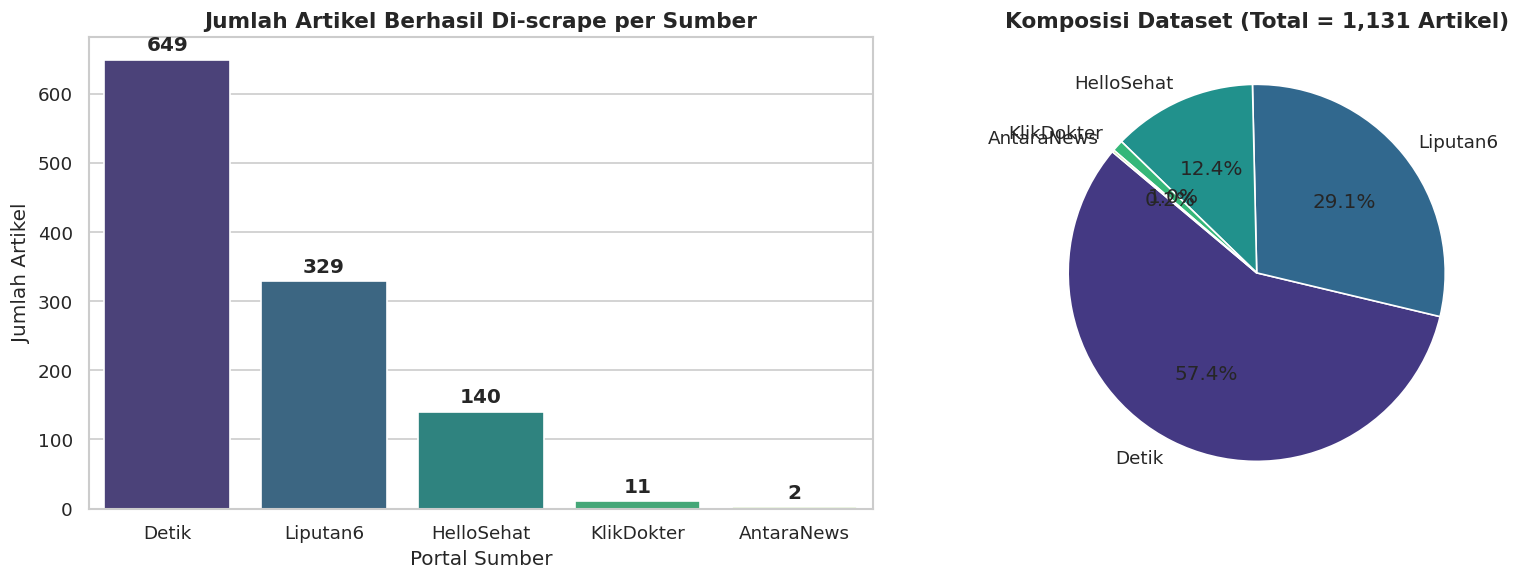

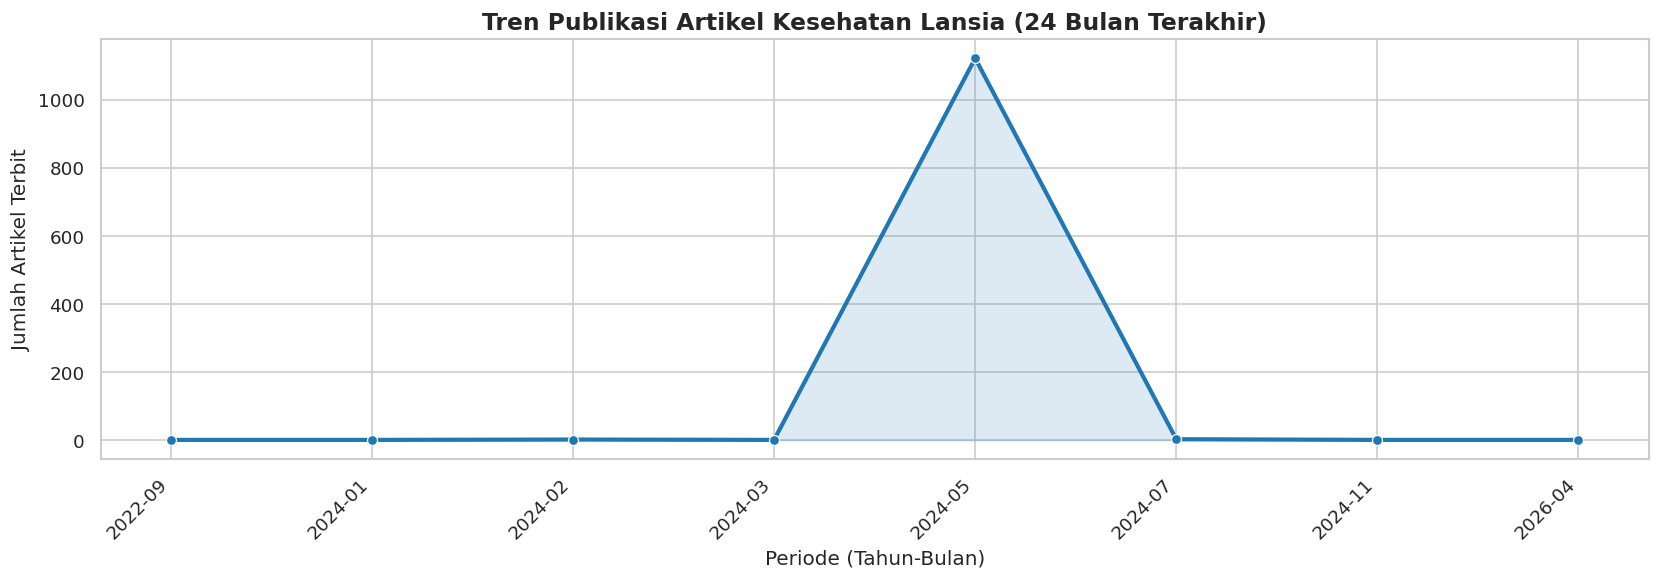

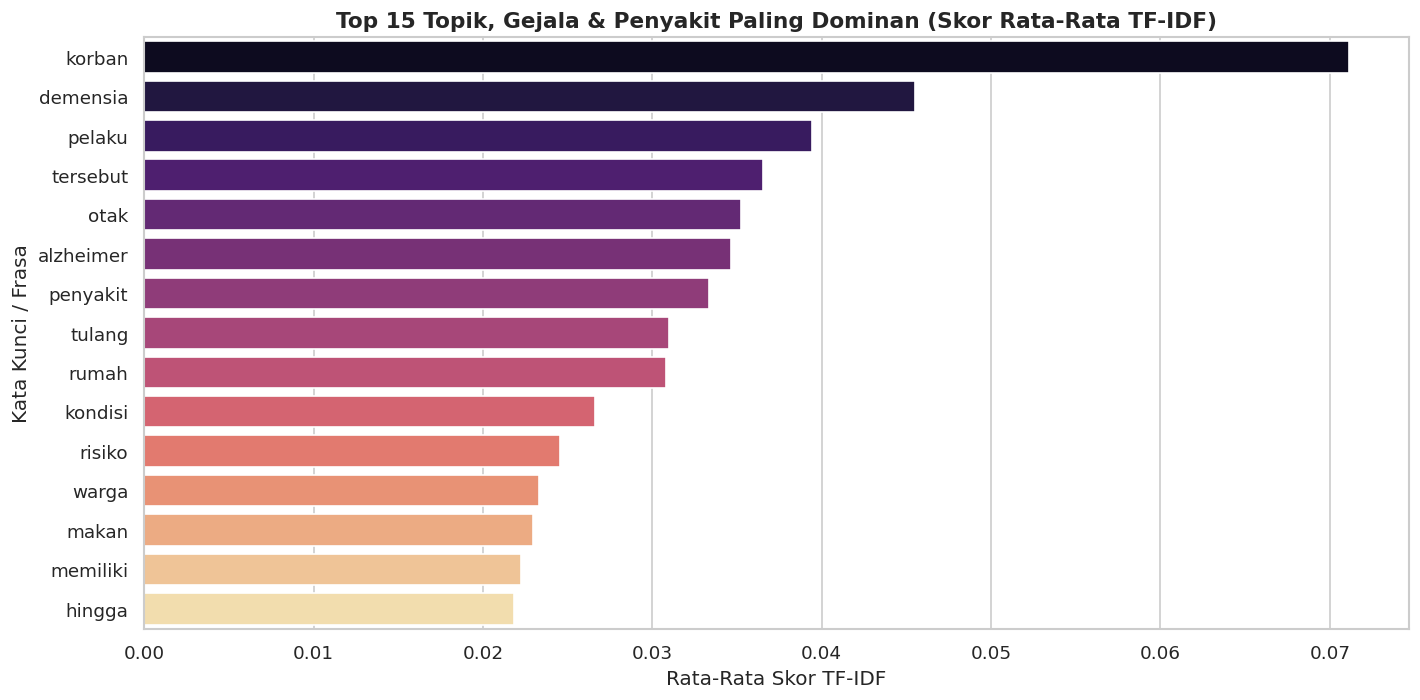

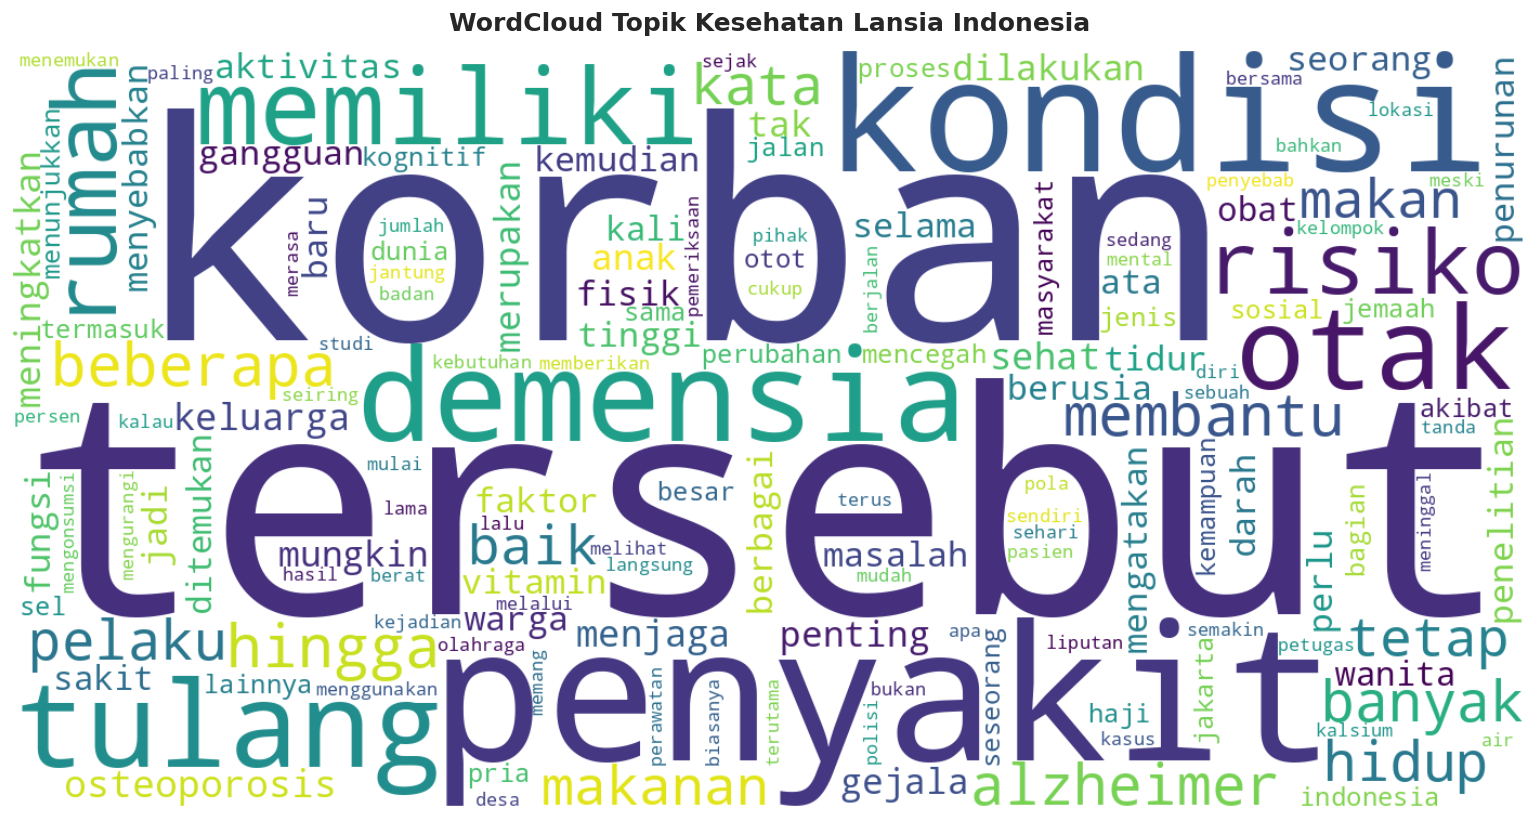

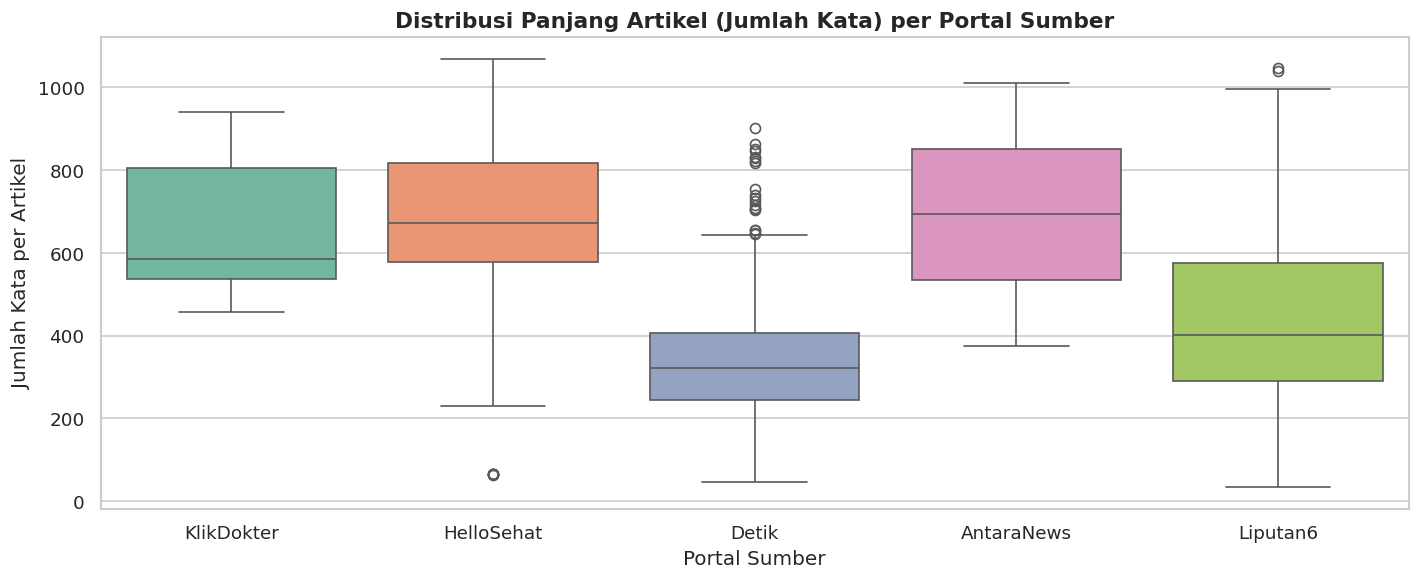

=== HASIL TOPIC MODELING (LDA - 5 KLASTER UTAMA) ===
Topik 1: tulang, osteoporosis, kondisi, penyakit | Kata kunci lengkap: tulang, osteoporosis, kondisi, penyakit, menyebabkan, beberapa, obat
Topik 2: demensia, otak, alzheimer, penyakit | Kata kunci lengkap: demensia, otak, alzheimer, penyakit, risiko, penelitian, tersebut
Topik 3: korban, pelaku, tersebut, rumah | Kata kunci lengkap: korban, pelaku, tersebut, rumah, warga, kemudian, ditemukan
Topik 4: makanan, makan, vitamin, menjaga | Kata kunci lengkap: makanan, makan, vitamin, menjaga, membantu, sehat, tetap
Topik 5: tersebut, jemaah, haji, indonesia | Kata kunci lengkap: tersebut, jemaah, haji, indonesia, rumah, keluarga, masyarakat


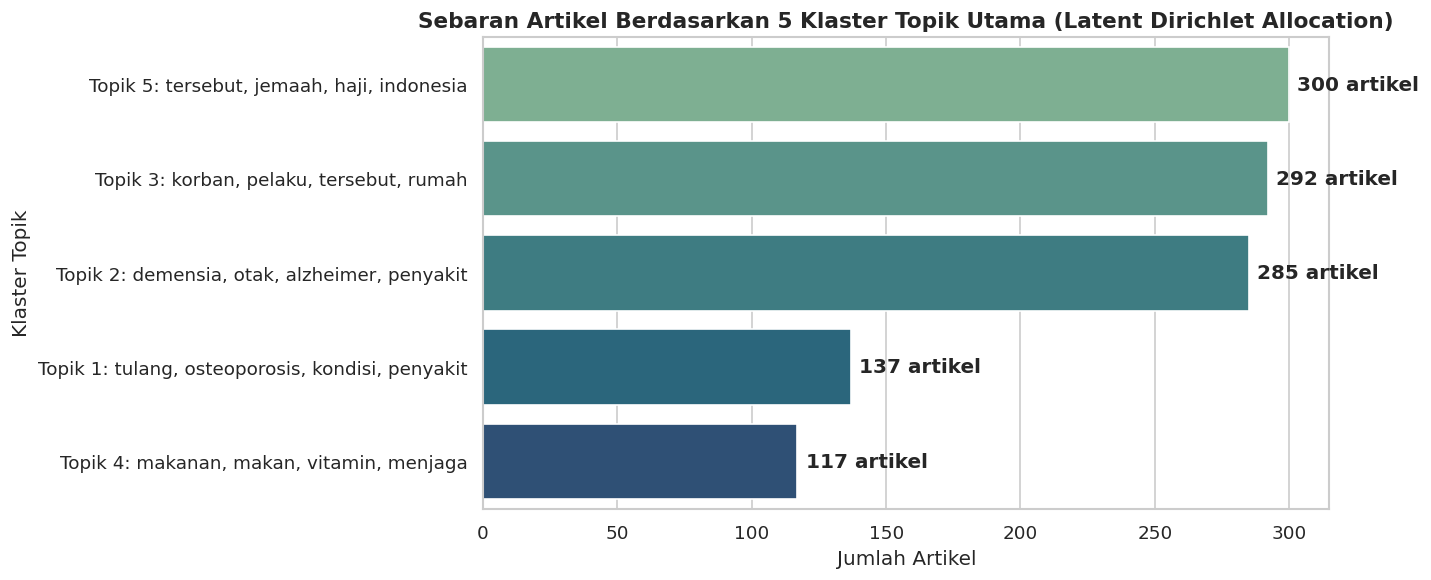


Seluruh proses Big Data selesai! Dataset final beserta klaster topik tersimpan di 'dataset_lansia_final_with_topics.csv'.


In [ ]:
df = pd.read_parquet("dataset_lansia_clean.parquet")
print(f"Memuat {len(df)} artikel bersih untuk visualisasi...\n")

# ==============================================================================
# VISUALISASI 1: Distribusi Jumlah Artikel per Sumber Portal
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sumber_counts = df["sumber"].value_counts()

sns.barplot(x=sumber_counts.index, y=sumber_counts.values, ax=axes[0], palette="viridis", hue=sumber_counts.index, legend=False)
axes[0].set_title("Jumlah Artikel Berhasil Di-scrape per Sumber", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Portal Sumber")
axes[0].set_ylabel("Jumlah Artikel")
for i, v in enumerate(sumber_counts.values):
    axes[0].text(i, v + (max(sumber_counts.values)*0.02), str(v), ha="center", fontweight="bold")

axes[1].pie(sumber_counts.values, labels=sumber_counts.index, autopct="%1.1f%%", startangle=140, colors=sns.color_palette("viridis", len(sumber_counts)))
axes[1].set_title(f"Komposisi Dataset (Total = {len(df):,} Artikel)", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("fig1_distribusi_sumber.png", dpi=300)
plt.show()

# ==============================================================================
# VISUALISASI 2: Tren Publikasi Artikel per Bulan (24 Bulan Terakhir)
# ==============================================================================
trend_df = df.groupby("tahun_bulan").size().reset_index(name="jumlah_artikel").sort_values("tahun_bulan")
trend_recent = trend_df.tail(24)

plt.figure(figsize=(14, 5))
sns.lineplot(data=trend_recent, x="tahun_bulan", y="jumlah_artikel", marker="o", linewidth=2.5, color="#1f77b4")
plt.fill_between(trend_recent["tahun_bulan"], trend_recent["jumlah_artikel"], alpha=0.15, color="#1f77b4")
plt.title("Tren Publikasi Artikel Kesehatan Lansia (24 Bulan Terakhir)", fontsize=14, fontweight="bold")
plt.xlabel("Periode (Tahun-Bulan)")
plt.ylabel("Jumlah Artikel Terbit")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("fig2_tren_publikasi.png", dpi=300)
plt.show()

# ==============================================================================
# VISUALISASI 3: Top 15 Kata Kunci / Penyakit Paling Dominan (TF-IDF Score)
# ==============================================================================
tfidf = TfidfVectorizer(max_features=1000, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(df["teks_clean"])
feature_names = np.array(tfidf.get_feature_names_out())
mean_tfidf = np.asarray(tfidf_matrix.mean(axis=0)).ravel()

top_idx = mean_tfidf.argsort()[::-1][:15]
top_terms = pd.DataFrame({
    "kata_kunci": feature_names[top_idx],
    "skor_tfidf": mean_tfidf[top_idx]
})

plt.figure(figsize=(12, 6))
sns.barplot(data=top_terms, x="skor_tfidf", y="kata_kunci", palette="magma", hue="kata_kunci", legend=False)
plt.title("Top 15 Topik, Gejala & Penyakit Paling Dominan (Skor Rata-Rata TF-IDF)", fontsize=13, fontweight="bold")
plt.xlabel("Rata-Rata Skor TF-IDF")
plt.ylabel("Kata Kunci / Frasa")
plt.tight_layout()
plt.savefig("fig3_top15_keywords.png", dpi=300)
plt.show()

# ==============================================================================
# VISUALISASI 4: WordCloud Korpus Kesehatan Lansia
# ==============================================================================
all_clean_text = " ".join(df["teks_clean"].tolist())
wc = WordCloud(
    width=1400,
    height=700,
    background_color="white",
    colormap="viridis",
    max_words=150,
    collocations=False
).generate(all_clean_text)

plt.figure(figsize=(14, 7))
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.title("WordCloud Topik Kesehatan Lansia Indonesia", fontsize=15, fontweight="bold", pad=12)
plt.tight_layout()
plt.savefig("fig4_wordcloud_lansia.png", dpi=300)
plt.show()

# ==============================================================================
# VISUALISASI 5: Distribusi Panjang Artikel (Jumlah Kata) per Sumber
# ==============================================================================
plt.figure(figsize=(12, 5))
upper_limit = df["jumlah_kata"].quantile(0.98)
sns.boxplot(data=df[df["jumlah_kata"] <= upper_limit], x="sumber", y="jumlah_kata", palette="Set2", hue="sumber", legend=False)
plt.title("Distribusi Panjang Artikel (Jumlah Kata) per Portal Sumber", fontsize=13, fontweight="bold")
plt.xlabel("Portal Sumber")
plt.ylabel("Jumlah Kata per Artikel")
plt.tight_layout()
plt.savefig("fig5_distribusi_panjang_artikel.png", dpi=300)
plt.show()

# ==============================================================================
# VISUALISASI 6: Topic Modeling (LDA - 5 Klaster Topik Kesehatan Lansia)
# ==============================================================================
N_TOPICS = 5
min_df_val = min(5, max(1, len(df) // 20))
count_vec = CountVectorizer(max_df=0.90, min_df=min_df_val, max_features=2000)
dtm = count_vec.fit_transform(df["teks_clean"])

lda = LatentDirichletAllocation(n_components=N_TOPICS, random_state=42, max_iter=15)
topic_distributions = lda.fit_transform(dtm)

vocab = count_vec.get_feature_names_out()
topic_labels = []
print("=== HASIL TOPIC MODELING (LDA - 5 KLASTER UTAMA) ===")
for idx, topic_weights in enumerate(lda.components_):
    top_words = [vocab[i] for i in topic_weights.argsort()[:-8:-1]]
    label = f"Topik {idx+1}: {', '.join(top_words[:4])}"
    topic_labels.append(label)
    print(f"{label} | Kata kunci lengkap: {', '.join(top_words)}")

df["klaster_topik"] = [topic_labels[i] for i in topic_distributions.argmax(axis=1)]
topic_counts = df["klaster_topik"].value_counts()

plt.figure(figsize=(12, 5))
sns.barplot(x=topic_counts.values, y=topic_counts.index, palette="crest", hue=topic_counts.index, legend=False)
plt.title("Sebaran Artikel Berdasarkan 5 Klaster Topik Utama (Latent Dirichlet Allocation)", fontsize=13, fontweight="bold")
plt.xlabel("Jumlah Artikel")
plt.ylabel("Klaster Topik")
for i, v in enumerate(topic_counts.values):
    plt.text(v + (max(topic_counts.values)*0.01), i, f"{v} artikel", va="center", fontweight="bold")
plt.tight_layout()
plt.savefig("fig6_topic_modeling_lda.png", dpi=300)
plt.show()

# Simpan dataset final yang sudah dilengkapi label klaster topik
df.to_csv("dataset_lansia_final_with_topics.csv", index=False, encoding="utf-8-sig")
print("\nSeluruh proses Big Data selesai! Dataset final beserta klaster topik tersimpan di 'dataset_lansia_final_with_topics.csv'.")